In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import iris
from iris.fileformats.um import structured_um_loading
import cftime
import numpy as np
import xarray_tools as xrt
import cftime, nc_time_axis, cf_units
from notebook_metadata import create_savefig
from pathlib import Path

savefig = create_savefig(dir='/scratch/tm70/mrd599/plots', nb='esm_historical_ozone_check.ipynb')

In [2]:
from dask.distributed import Client
client = Client(threads_per_worker = 1)

In [3]:
area_esm15 = xr.open_dataset('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_ACCESS-ESM1-5_piControl_r1i1p1f1_gn.nc').areacella


In [ ]:
# Loadging ancillary files is much slower than loading a netCDF version. Evan later calculations are faster with the
# netCDF version

# This is marginally faster to load
# with structured_um_loading():
#     ozone_esm15 = iris.load_cube('/g/data/vk83/configurations/inputs/access-esm1p5/modern/historical/atmosphere/forcing/global.N96/2021.06.22/ozone_1849_2015_ESM1.anc')
#     ozone_esm16 = iris.load_cube('/g/data/vk83/configurations/inputs/access-esm1p6/modern/historical/atmosphere/forcing/global.N96/2026.03.03/ozone_1849_2023_cmip7.anc')
#     ozone_esm16 = iris.load_cube('/scratch/tm70/mrd599/oztest')
# # iris rechunking doesn't give the specified chunk sizes for some reason, rechunk in xarray
# ozone_esm15 = xr.DataArray.from_iris(ozone_esm15).squeeze().rename({'latitude':'lat'}).chunk({"time":12, "model_level_number":-1, "lat":-1})
# ozone_esm16 = xr.DataArray.from_iris(ozone_esm16).squeeze().rename({'latitude':'lat'}).chunk({"time":12, "model_level_number":-1, "lat":-1})

ozone_esm15 = xr.open_dataset('/scratch/tm70/mrd599/esm16_ozone/ozone_1849_2015_ESM1.nc', chunks={"time":12, "model_level_number":-1, "lat":-1}).squeeze().fld_s00i060
ozone_esm16 = xr.open_dataset('/scratch/tm70/mrd599/esm16_ozone/ozone_1849_2023_cmip7.nc', chunks={"time":12, "model_level_number":-1, "lat":-1}).squeeze().fld_s00i060

/jobfs/181098025.gadi-pbs/ipykernel_2099451/2316374338.py:14: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ozone_esm16 = xr.open_dataset('/scratch/tm70/mrd599/ozone_1849_2023_cmip7.nc', chunks={"time":12, "model_level_number":-1, "lat":-1}).squeeze().fld_s00i060
/jobfs/181098025.gadi-pbs/ipykernel_2099451/2316374338.py:14: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, con

In [6]:
ozone_esm15_a = xrt.annual_mean(ozone_esm15, original_time_axis=True).compute()
ozone_esm16_a = xrt.annual_mean(ozone_esm16, original_time_axis=True).compute()

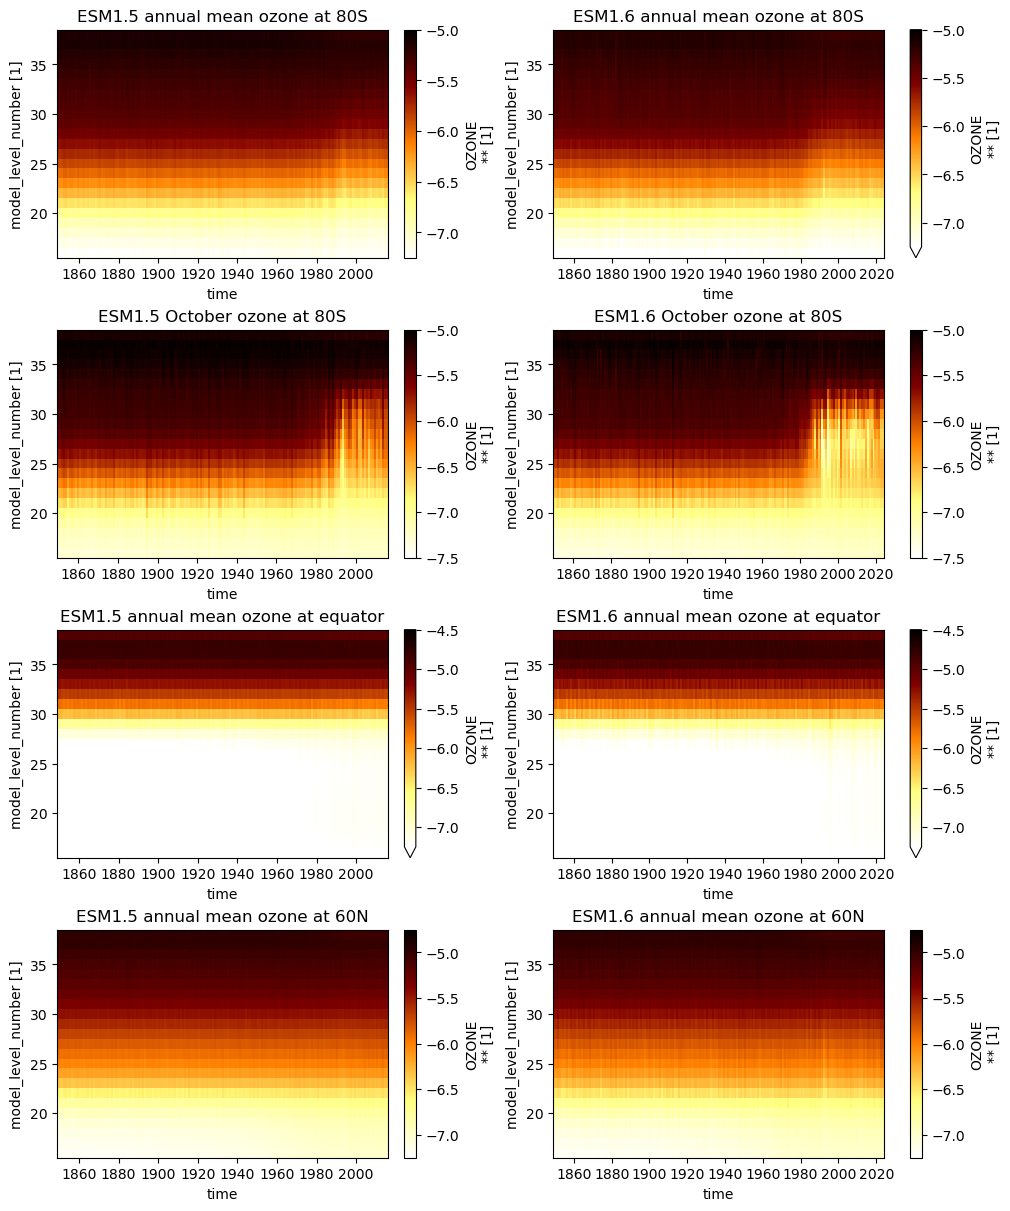

In [7]:
fig, axes = plt.subplots(4,2,layout='constrained',figsize=(10,12))
axes = axes.flatten()
vmin = -7.25
vmax = -5
ax = axes[0]
kmin=15
np.log10(ozone_esm15_a)[:,kmin:].sel(lat=-80).plot(x='year',ax=ax, vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.5 annual mean ozone at 80S')
ax = axes[1]
np.log10(ozone_esm16_a)[:,kmin:].sel(lat=-80).plot(x='year',ax=ax, vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.6 annual mean ozone at 80S')

vmin = -7.5
vmax = -5
ax = axes[2]
np.log10(ozone_esm15)[9::12,kmin:].sel(lat=-80).plot(x='time',ax=ax, vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.5 October ozone at 80S')
ax = axes[3]
np.log10(ozone_esm16)[9::12,kmin:].sel(lat=-80).plot(x='time',ax=ax, vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.6 October ozone at 80S')

vmin = -7.25
vmax = -4.5
ax = axes[4]
kmin=15
np.log10(ozone_esm15_a)[:,kmin:].sel(lat=0).plot(x='year',ax=ax,vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.5 annual mean ozone at equator')
ax = axes[5]
np.log10(ozone_esm16_a)[:,kmin:].sel(lat=0).plot(x='year',ax=ax, vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.6 annual mean ozone at equator')

vmin = -7.25
vmax = -4.75
ax = axes[6]
kmin=15
np.log10(ozone_esm15_a)[:,kmin:].sel(lat=60).plot(x='year',ax=ax,vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.5 annual mean ozone at 60N')
ax = axes[7]
np.log10(ozone_esm16_a)[:,kmin:].sel(lat=60).plot(x='year',ax=ax, vmin=vmin, vmax=vmax, cmap='afmhot_r')
ax.set_title('ESM1.6 annual mean ozone at 60N')
savefig('ozone_series.png')

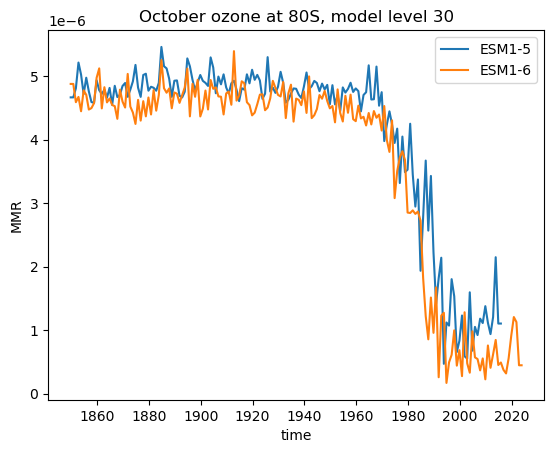

In [8]:
fig, axes = plt.subplots()
k=29
ozone_esm15[9::12,k].sel(lat=-80).plot(label='ESM1-5')
ozone_esm16[9::12,k].sel(lat=-80).plot(label='ESM1-6')
axes.set_title(f'October ozone at 80S, model level {k+1}')
axes.set_ylabel('MMR')
axes.legend()

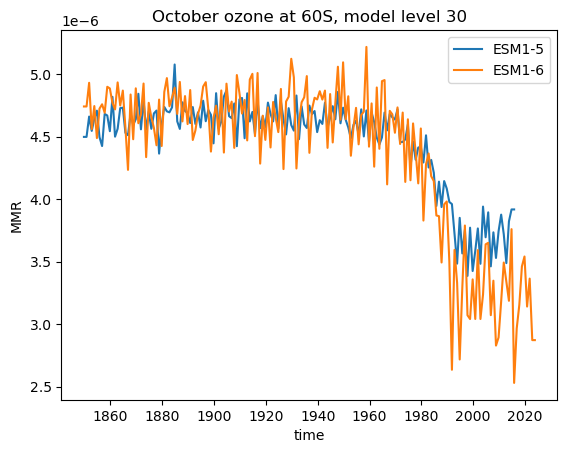

In [9]:
fig, axes = plt.subplots()
k=29
ozone_esm15[9::12,k].sel(lat=-60).plot(label='ESM1-5')
ozone_esm16[9::12,k].sel(lat=-60).plot(label='ESM1-6')
axes.set_title(f'October ozone at 60S, model level {k+1}')
axes.set_ylabel('MMR')
axes.legend()

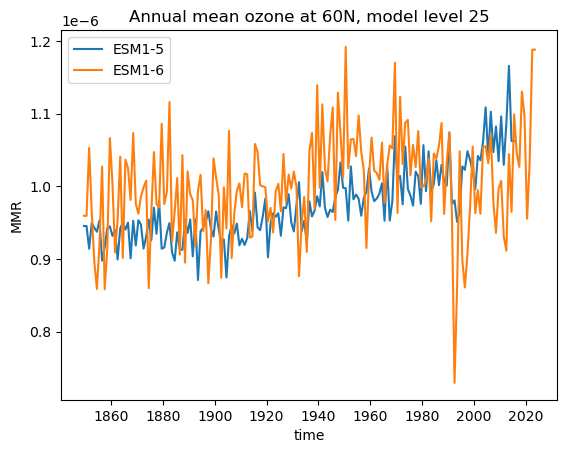

In [242]:
fig, axes = plt.subplots()
k=24
ozone_esm15_a[:,k].sel(lat=60).plot(label='ESM1-5')
ozone_esm16_a[:,k].sel(lat=60).plot(label='ESM1-6')
axes.set_title(f'Annual mean ozone at 60N, model level {k+1}')
axes.set_ylabel('MMR')
axes.legend()

In [10]:
ozone_cmip7 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/FZJ/FZJ-CMIP-ozone-2-0/atmos/mon/vmro3/gn/v20260211/vmro3_input4MIPs_ozone_CMIP_FZJ-CMIP-ozone-2-0*').vmro3

/jobfs/181098025.gadi-pbs/ipykernel_2099451/989899155.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ozone_cmip7 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/FZJ/FZJ-CMIP-ozone-2-0/atmos/mon/vmro3/gn/v20260211/vmro3_input4MIPs_ozone_CMIP_FZJ-CMIP-ozone-2-0*').vmro3


In [11]:
ozone_cmip7z = ozone_cmip7.mean('lon').compute()

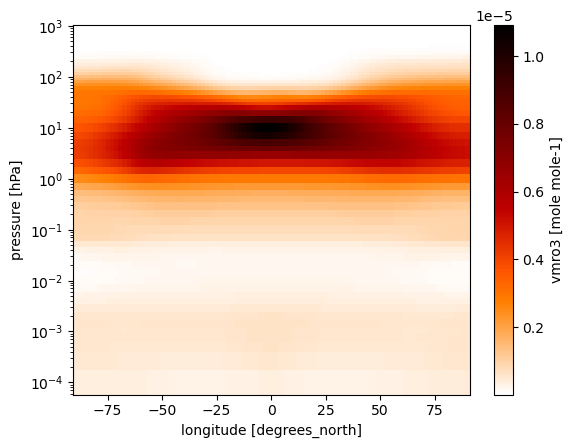

In [12]:
ozone_cmip7z[:12].mean('time').plot(yscale='log', cmap='gist_heat_r')

(1000, 0.01)

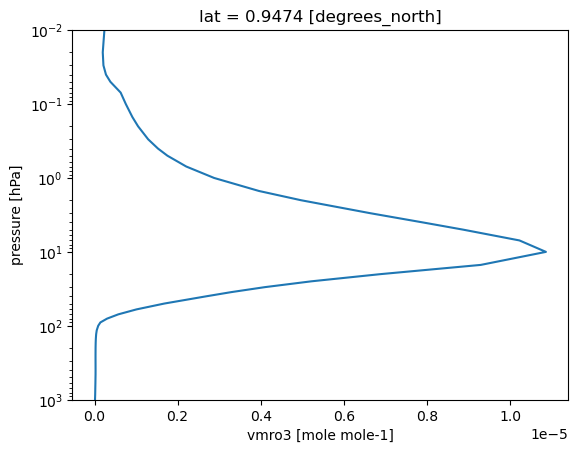

In [13]:
fig, axes = plt.subplots()
ozone_cmip7z[:12].mean('time').sel(lat=0, method='nearest').plot(y='plev', yscale='log') # , cmap='gist_heat_r')
axes.set_ylim(1000, 0.01)

In [14]:
# Ozone data is VMR. Conversion to MMR factor
conv_factor = 48.0 / 28.966

# Factor for conversion of kg/m^2 to DU from https://sacs.aeronomie.be/info/dobson.php
du_factor = 2.1415e-5

# Mass of each layer
# Midpoint pressures
plev = 100*ozone_cmip7.plev.values  # Pa
pmid = 0.5*(plev[1:] + plev[:-1])
pmidx = np.concatenate(([1e5], pmid, [0.]))
dp = -np.diff(pmidx)
grav = 9.806
dmass = dp / grav


In [15]:
# For a top at 100 Pa to approximately match ESM
dmassx = np.array(dmass)
dmassx[41:] = 0.

In [16]:
ozone_mass_cmip7 = conv_factor*(ozone_cmip7z* dmass[np.newaxis,:, np.newaxis]).sum('plev')
ozone_mass_cmip7x = conv_factor*(ozone_cmip7z* dmassx[np.newaxis,:, np.newaxis]).sum('plev')

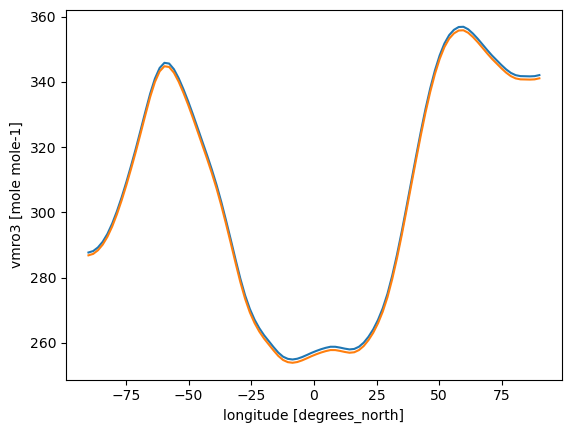

In [17]:
(ozone_mass_cmip7[:12].mean('time')/du_factor).plot()
(ozone_mass_cmip7x[:12].mean('time')/du_factor).plot()

In [18]:
# Get pressure at rho levels to calculate an integral of the model data.
# Use 2000 from the historical run
req_vars = ['fld_s00i407', 'fld_s00i408', 'fld_s00i409']
def _preprocess(ds):
    """Keep only required variables to save memory"""
    # Select only variables that exist in the file to avoid KeyErrors
    vars_to_keep = [v for v in req_vars if v in ds.variables]
    return ds[vars_to_keep]

d = xr.open_mfdataset('/g/data/p73/archive/CMIP7/ACCESS-ESM1-6/production/ensemble-concentrations-historical/historical-historical-1.1-r1i1p1f1-01409bc3/historical-historical-1.1-r1i1p1f1-01409bc3/output150/atmosphere/netCDF/aiihca.pa-2000*_mon.nc',
            preprocess=_preprocess, parallel=True, data_vars='minimal', coords='minimal', compat='override' )

In [19]:
prho = d.fld_s00i407.mean('lon').compute()
ptheta = d.fld_s00i408.mean('lon').compute()
ps = d.fld_s00i409.mean('lon').compute()

dp_esm = prho[:,:-1].data - prho[:,1:]
dp_esm[:,0] = ps.data - prho[:,1].data
dp_top = 2*(prho[:,-1].data - ptheta[:,-1].data)
dp_esm= np.concatenate((dp_esm, dp_top[:, np.newaxis]), axis=1)
dmass_esm = dp_esm / grav
dmass_esm_ann = dmass_esm.mean(axis=0)


In [20]:
ozone_mass_esm = (ozone_esm16_a * dmass_esm_ann).sum('model_level_number')
ozone_mass_esm15 = (ozone_esm15_a * dmass_esm_ann).sum('model_level_number')

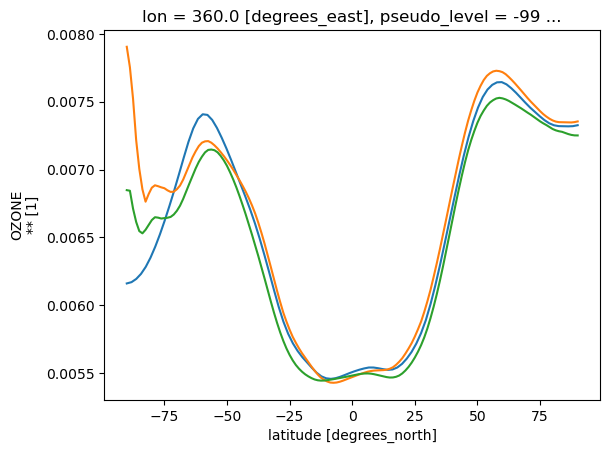

In [21]:
(ozone_mass_cmip7.sel(time="1850").mean('time')).plot()
(ozone_mass_esm.sel(year="1850")).plot()
(ozone_mass_esm15.sel(year="1850")).plot()

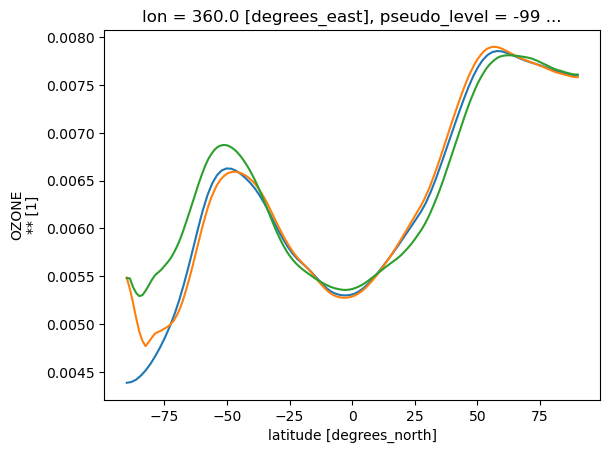

In [259]:
(ozone_mass_cmip7.sel(time="2000").mean('time')).plot()
(ozone_mass_esm.sel(year="2000")).plot()
(ozone_mass_esm15.sel(year="2000")).plot()

(1000, 0.01)

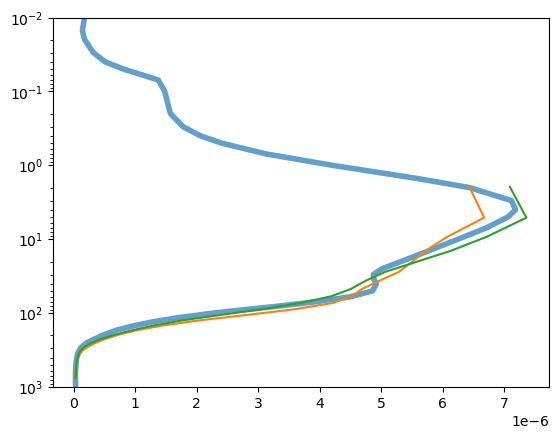

In [260]:
fig, axes = plt.subplots()
# plt.semilogy(conv_factor*ozone_cmip7z[:12].mean('time').sel(lat=0, method='nearest'), ozone_cmip7.plev, lw=4, alpha=0.7)
# plt.semilogy(ozone_esm16_a[0].sel(lat=0, method='nearest'), 0.01*ptheta.mean('time').sel(lat=0, method='nearest'))
plt.semilogy(conv_factor*ozone_cmip7z[:12].mean('time').sel(lat=-85, method='nearest'), ozone_cmip7.plev, lw=4, alpha=0.7)
plt.semilogy(ozone_esm16_a[0].sel(lat=-85, method='nearest'), 0.01*ptheta.mean('time').sel(lat=-85, method='nearest'))
plt.semilogy(ozone_esm15_a[0].sel(lat=-85, method='nearest'), 0.01*ptheta.mean('time').sel(lat=-85, method='nearest'))
axes.set_ylim(1000, 0.01)

(1000, 0.01)

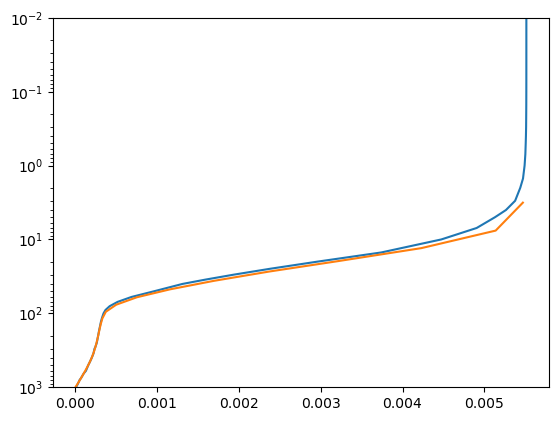

In [261]:
fig, axes = plt.subplots()
plt.semilogy((conv_factor*ozone_cmip7z[:12].mean('time').sel(lat=0, method='nearest') * dmass).cumsum(), ozone_cmip7.plev)
plt.semilogy((ozone_esm16_a[0]*dmass_esm_ann).sel(lat=0, method='nearest').cumsum(), 0.01*ptheta.mean('time').sel(lat=0, method='nearest'))

axes.set_ylim(1000, 0.01)

(1000, 0.01)

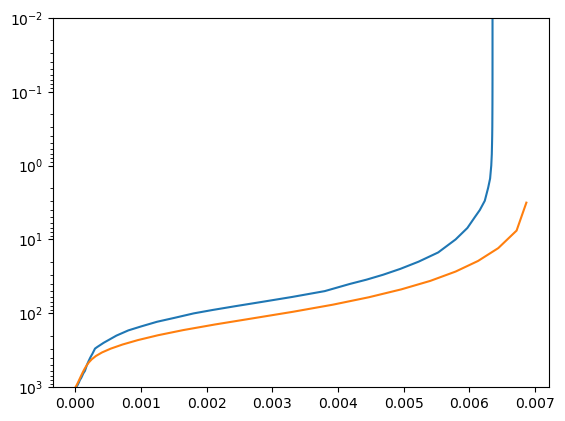

In [262]:
fig, axes = plt.subplots()
plt.semilogy((conv_factor*ozone_cmip7z[:12].mean('time').sel(lat=-80, method='nearest') * dmass).cumsum(), ozone_cmip7.plev)
plt.semilogy((ozone_esm16_a[0]*dmass_esm_ann).sel(lat=-80, method='nearest').cumsum(), 0.01*ptheta.mean('time').sel(lat=0, method='nearest'))

axes.set_ylim(1000, 0.01)

In [22]:
ozone_mass_esm = ozone_esm16[:,0].copy() # To get a dataset of correct shape
#  Do the pressure weighting by year
for i in range(0,len(ozone_esm16), 12):
    ozone_mass_esm[i:i+12] = (ozone_esm16[i:i+12] * dmass_esm).sum('model_level_number')
_ = ozone_mass_esm.load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 45.60 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


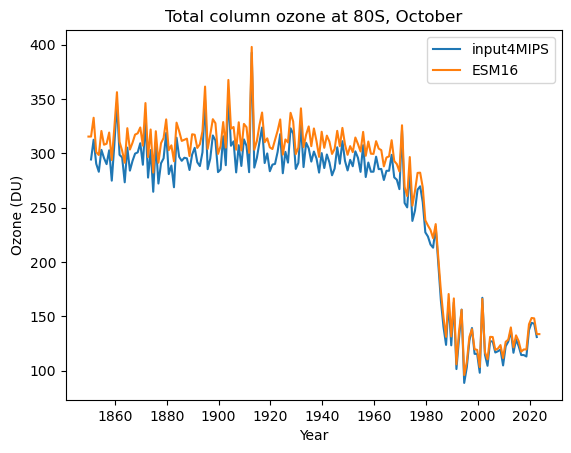

In [23]:
fig, axes = plt.subplots()
(ozone_mass_cmip7[9::12].convert_calendar(calendar='gregorian').sel(lat=-80, method='nearest')/du_factor).plot(label='input4MIPS')
(ozone_mass_esm[9::12].sel(lat=-80, method='nearest')/du_factor).plot(label='ESM16')
axes.set_ylabel('Ozone (DU)')
axes.set_xlabel('Year')
axes.set_title('Total column ozone at 80S, October')
axes.legend()

In [24]:
ozone_cmip7_scen = {}
scenarios = ["h", "hl", "l", "ln", "m", "ml", "vl"]
for s in scenarios:
    print(s)
    ozone_cmip7_scen[s] = xr.open_mfdataset(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/FZJ/FZJ-CMIP-ozone-{s}-1-0/atmos/mon/vmro3/gn/v*/vmro3_input4MIPs_ozone_ScenarioMIP*nc').vmro3
ozone_cmip7_scen_z = {s: ozone_cmip7_scen[s].mean('lon').compute() for s in scenarios}
ozone_mass_cmip7_scen = {s: conv_factor*(ozone_cmip7_scen_z[s]* dmass[np.newaxis,:, np.newaxis]).sum('plev').compute() for s in scenarios}


h
hl


/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ozone_cmip7_scen[s] = xr.open_mfdataset(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/FZJ/FZJ-CMIP-ozone-{s}-1-0/atmos/mon/vmro3/gn/v*/vmro3_input4MIPs_ozone_ScenarioMIP*nc').vmro3
/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings

l
ln


/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ozone_cmip7_scen[s] = xr.open_mfdataset(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/FZJ/FZJ-CMIP-ozone-{s}-1-0/atmos/mon/vmro3/gn/v*/vmro3_input4MIPs_ozone_ScenarioMIP*nc').vmro3
/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings

m
ml


/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ozone_cmip7_scen[s] = xr.open_mfdataset(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/FZJ/FZJ-CMIP-ozone-{s}-1-0/atmos/mon/vmro3/gn/v*/vmro3_input4MIPs_ozone_ScenarioMIP*nc').vmro3
/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings

vl


/jobfs/181098025.gadi-pbs/ipykernel_2099451/4139060369.py:5: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ozone_cmip7_scen[s] = xr.open_mfdataset(f'/g/data/qv56/replicas/input4MIPs/CMIP7/ScenarioMIP/FZJ/FZJ-CMIP-ozone-{s}-1-0/atmos/mon/vmro3/gn/v*/vmro3_input4MIPs_ozone_ScenarioMIP*nc').vmro3


(85.0, 330.0)

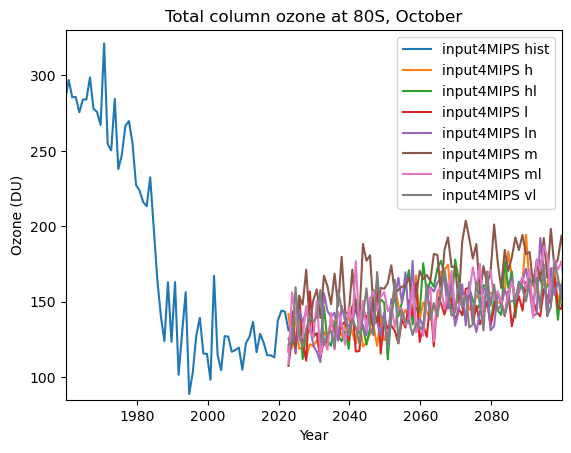

In [25]:
fig, axes = plt.subplots()
(ozone_mass_cmip7[9::12].convert_calendar(calendar='gregorian').sel(lat=-80, method='nearest')/du_factor).plot(label='input4MIPS hist')
for s in scenarios:
    (ozone_mass_cmip7_scen[s][9::12].convert_calendar(calendar='gregorian').sel(lat=-80, method='nearest')/du_factor).plot(label=f'input4MIPS {s}')
axes.legend()
axes.set_ylabel('Ozone (DU)')
axes.set_xlabel('Year')
axes.set_title('Total column ozone at 80S, October')
taxis = cf_units.Unit("days since 1970-01-01 00:00", calendar="noleap")
t0 = taxis.date2num(cftime.DatetimeNoLeap(1960,1,1,0,0,0))
t1 = taxis.date2num(cftime.DatetimeNoLeap(2100,1,1,0,0,0))
axes.set_xlim(t0,t1)
axes.set_ylim(85,330)

(200.0, 310.0)

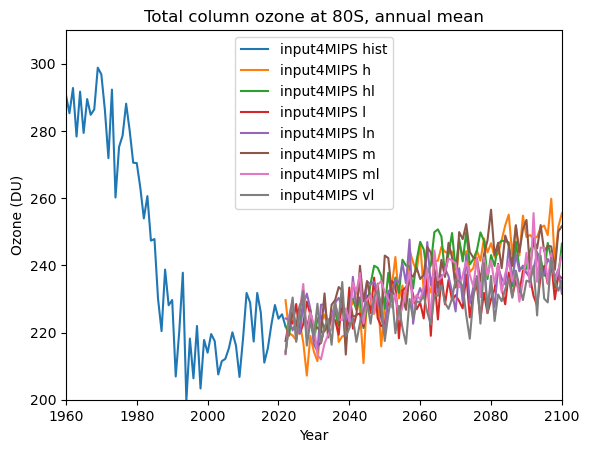

In [26]:
fig, axes = plt.subplots()
(xrt.annual_mean(ozone_mass_cmip7).sel(lat=-80, method='nearest')/du_factor).plot(label='input4MIPS hist')
for s in scenarios:
    (xrt.annual_mean(ozone_mass_cmip7_scen[s]).sel(lat=-80, method='nearest')/du_factor).plot(label=f'input4MIPS {s}')
axes.legend()
axes.set_ylabel('Ozone (DU)')
axes.set_xlabel('Year')
axes.set_title('Total column ozone at 80S, annual mean')
axes.set_xlim(1960,2100)
axes.set_ylim(200,310)

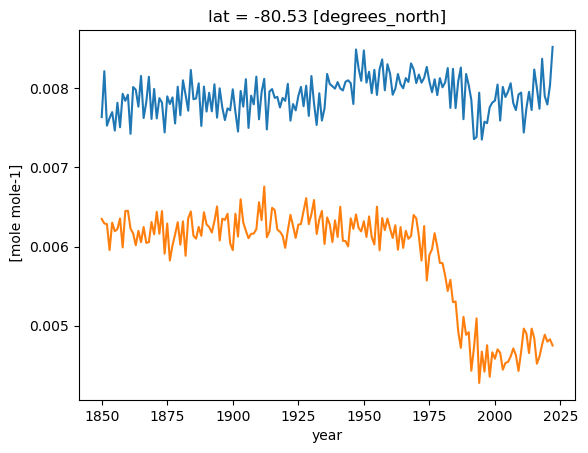

In [27]:
xrt.annual_mean(ozone_mass_cmip7).sel(lat=60,method='nearest').plot()
xrt.annual_mean(ozone_mass_cmip7).sel(lat=-80,method='nearest').plot()

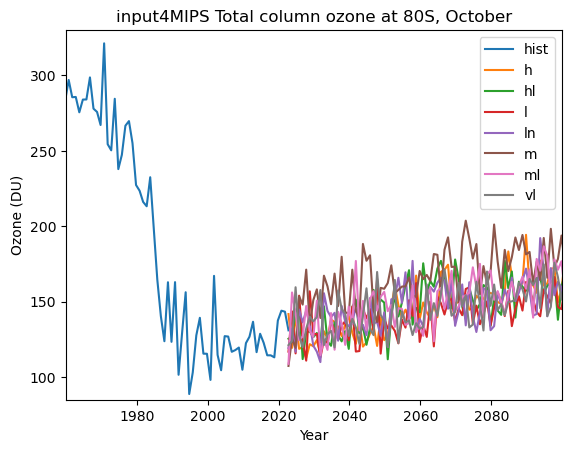

In [28]:
fig, axes = plt.subplots()
(ozone_mass_cmip7[9::12].convert_calendar(calendar='gregorian').sel(lat=-80, method='nearest')/du_factor).plot(label='hist')
for s in scenarios:
    (ozone_mass_cmip7_scen[s][9::12].convert_calendar(calendar='gregorian').sel(lat=-80, method='nearest')/du_factor).plot(label=f'{s}')
axes.legend()
axes.set_ylabel('Ozone (DU)')
axes.set_xlabel('Year')
axes.set_title('input4MIPS Total column ozone at 80S, October')
taxis = cf_units.Unit("days since 1970-01-01 00:00", calendar="noleap")
t0 = taxis.date2num(cftime.DatetimeNoLeap(1960,1,1,0,0,0))
t1 = taxis.date2num(cftime.DatetimeNoLeap(2100,1,1,0,0,0))
axes.set_xlim(t0,t1)
axes.set_ylim(85,330)
savefig('ozone_80S_scen.png')

In [30]:
ozone_esm16_scen = {}
for s in scenarios:
    ozone_esm16_scen[s] = xr.open_dataset(f'/scratch/tm70/mrd599/esm16_ozone/ozone_{s}_2022_2150_cmip7.nc', chunks={"time":12, "model_level_number":-1, "lat":-1}).squeeze().field60
    # ozone_esm16_scen[s] = xr.open_dataset(f'/scratch/tm70/mrd599/esm16_ozone/ozone_{s}_2022_2150_cmip7.nc', chunks={"time":12, "model_level_number":-1, "lat":-1}).squeeze().fld_s00i060

/jobfs/181098025.gadi-pbs/ipykernel_2099451/511809081.py:3: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ozone_esm16_scen[s] = xr.open_dataset(f'/scratch/tm70/mrd599/esm16_ozone/ozone_{s}_2022_2150_cmip7.nc', chunks={"time":12, "model_level_number":-1, "lat":-1}).squeeze().field60
/jobfs/181098025.gadi-pbs/ipykernel_2099451/511809081.py:3: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performa

In [31]:
ozone_mass_esm_scen = {}
for s in scenarios:
    print(s)
    mass_esm = ozone_esm16_scen[s][:,0].copy()
    #  Do the pressure weighting by year
    for i in range(0,len(mass_esm), 12):
        mass_esm[i:i+12] = (ozone_esm16_scen[s][i:i+12] * dmass_esm).sum('model_level_number')
    ozone_mass_esm_scen[s] = mass_esm
    _ = ozone_mass_esm_scen[s].load()


h


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 33.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


hl


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 33.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


l


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 33.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


ml


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 33.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


vl


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 33.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


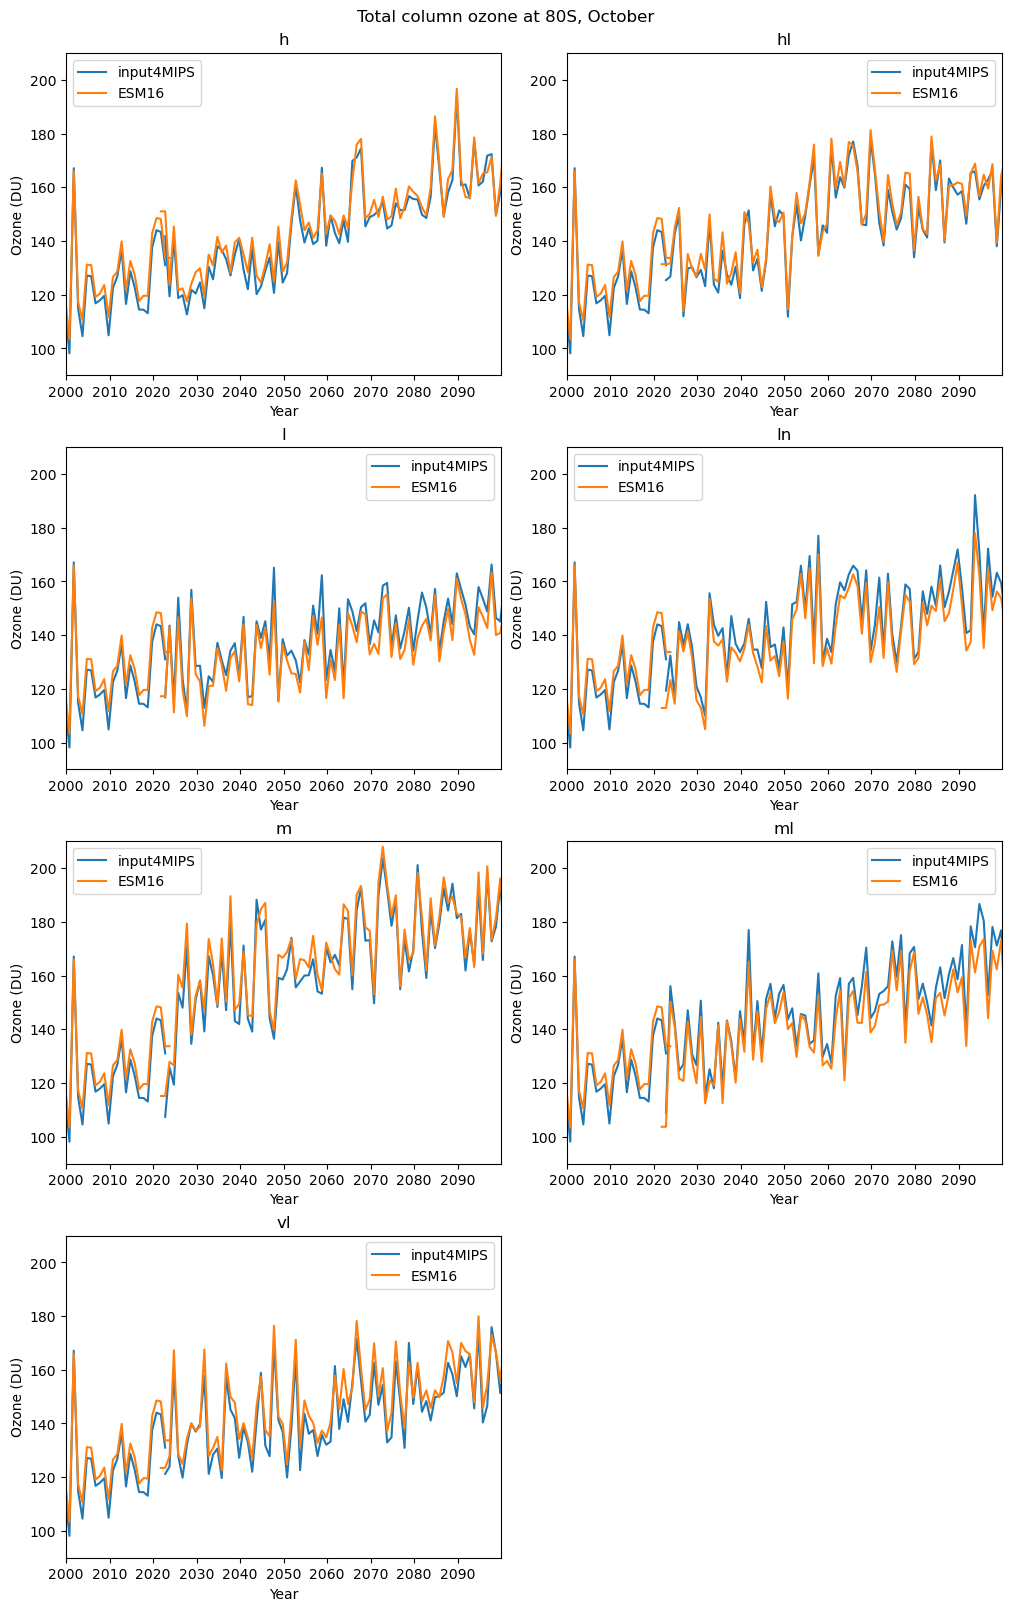

In [ ]:
mosaic = [ ['a', 'b'], ['c', 'd'], ['e', 'f'], ['g', '.']]
letters = ['a', 'b', 'c', 'd', 'e', 'f', 'g']
fig, axes = plt.subplot_mosaic(mosaic, layout='constrained', figsize=(10,16))
lat = -80
fig.suptitle('Total column ozone at 80S, October')
for i, s in enumerate(scenarios):
    ax = axes[letters[i]]
    (ozone_mass_cmip7[9::12].convert_calendar(calendar='gregorian').sel(lat=lat, method='nearest')/du_factor).plot(ax=ax, label='input4MIPS')
    (ozone_mass_esm[9::12].sel(lat=lat, method='nearest')/du_factor).plot(ax=ax, label='ESM16')
    (ozone_mass_cmip7_scen[s][9::12].convert_calendar(calendar='gregorian').sel(lat=lat, method='nearest')/du_factor).plot(ax=ax, label=None, color='C0')
    (ozone_mass_esm_scen[s][9::12].sel(lat=lat, method='nearest')/du_factor).plot(ax=ax, label=None, color='C1')
    ax.legend()
    taxis = cf_units.Unit("days since 1970-01-01 00:00", calendar="noleap")
    t0 = taxis.date2num(cftime.DatetimeNoLeap(2000,1,1,0,0,0))
    t1 = taxis.date2num(cftime.DatetimeNoLeap(2100,1,1,0,0,0))
    ax.set_xlim(t0,t1)
    ax.set_ylabel('Ozone (DU)')
    ax.set_xlabel('Year')
    ax.set_ylim(90,210)
    ax.set_title(s)

savefig('ozone_scen_timeseries.png')


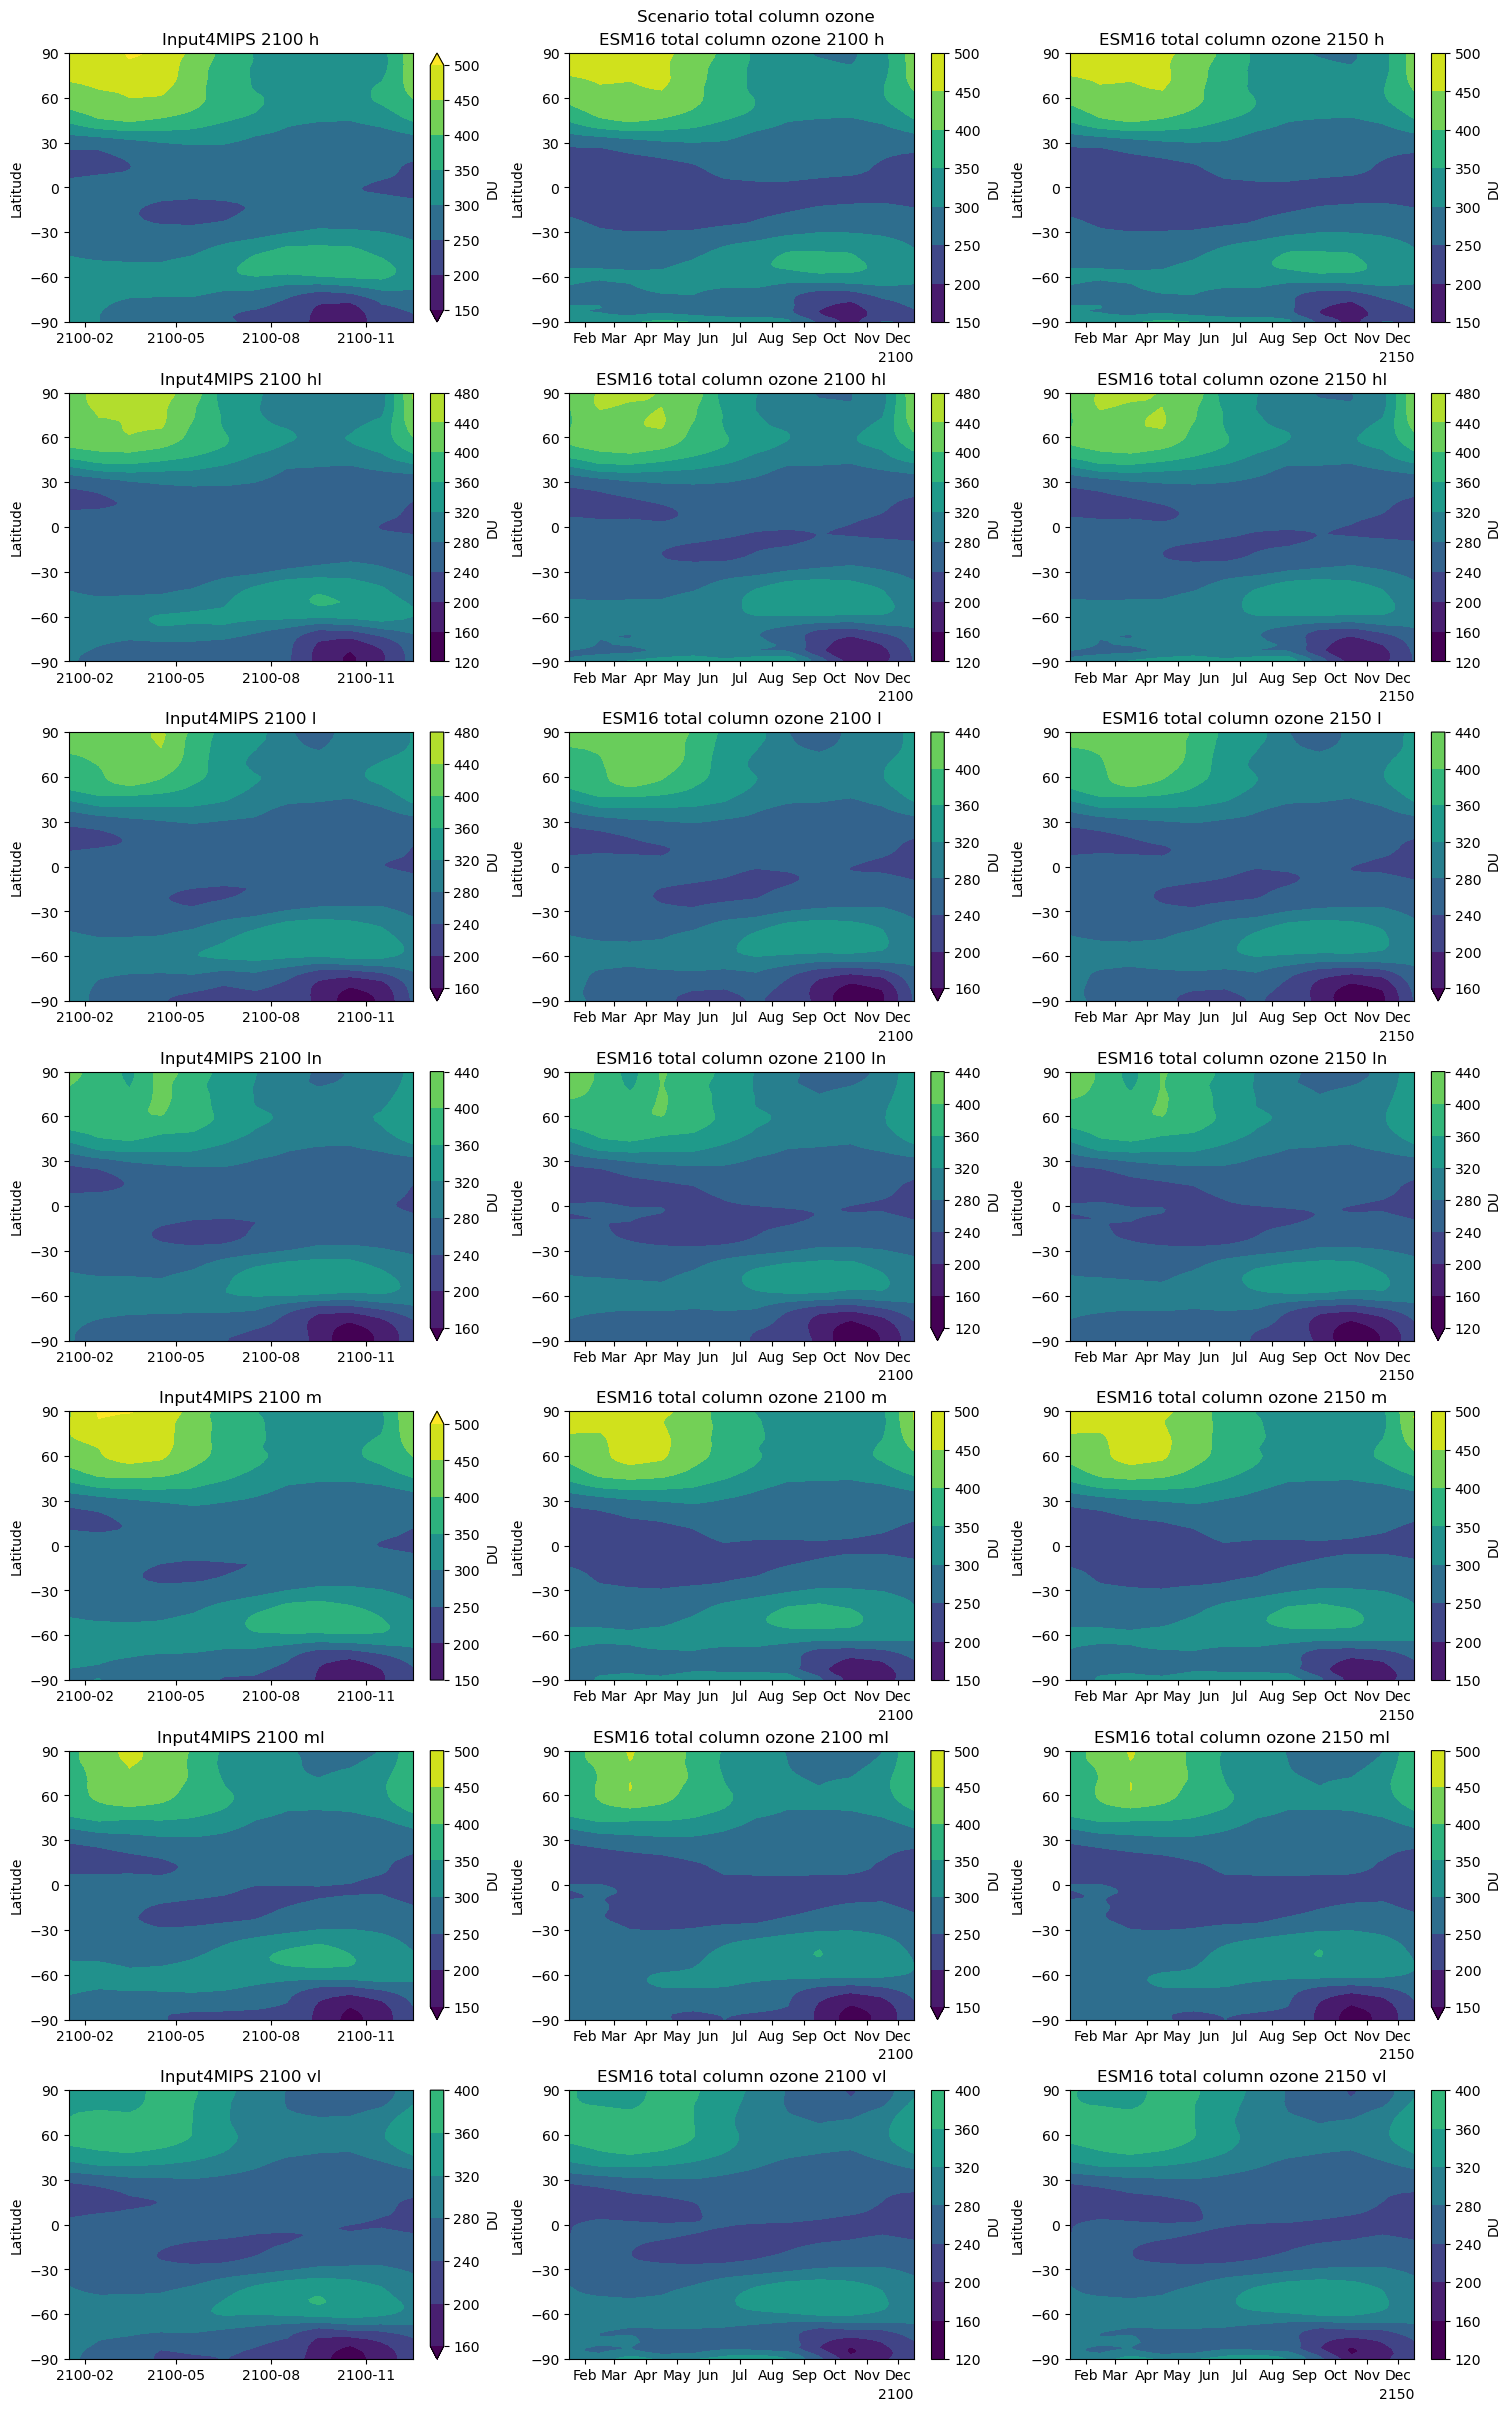

In [35]:
fig, axes = plt.subplots(7,3,layout='constrained',figsize=(15,24))
axes = axes.flat
vmin, vmax = 150, 500
cbar_kwargs = {'label':'DU'}
fig.suptitle('Scenario total column ozone')
iax = 0
for s in scenarios:
    ax = axes[iax]
    (ozone_mass_cmip7_scen[s].sel(time="2100")/du_factor).plot.contourf(ax=ax, x='time', cbar_kwargs=cbar_kwargs,
                                                                vmin=vmin, vmax=vmax)
    ax.set_title(f'Input4MIPS 2100 {s}')
    ax.set_ylabel('Latitude')
    ax.set_xlabel('')
    ax.set_ylim(-90,90)
    ax.set_yticks(np.linspace(-90,90,7))

    iax += 1
    ax = axes[iax]
    (ozone_mass_esm_scen[s].sel(time="2100")/du_factor).plot.contourf(ax=ax, x='time', cbar_kwargs=cbar_kwargs,
                                                                vmin=vmin, vmax=vmax)
    ax.set_title(f'ESM16 total column ozone 2100 {s}')
    ax.set_ylabel('Latitude')
    ax.set_xlabel('')
    ax.set_xlabel('')
    ax.set_ylim(-90,90)
    ax.set_yticks(np.linspace(-90,90,7))

    iax += 1
    ax = axes[iax]
    (ozone_mass_esm_scen[s].sel(time="2150")/du_factor).plot.contourf(ax=ax, x='time', cbar_kwargs=cbar_kwargs,
                                                                vmin=vmin, vmax=vmax)
    ax.set_title(f'ESM16 total column ozone 2150 {s}')
    ax.set_ylabel('Latitude')
    ax.set_xlabel('')
    ax.set_xlabel('')
    ax.set_ylim(-90,90)
    ax.set_yticks(np.linspace(-90,90,7))
    iax += 1

savefig('ozone_scen_2100.png')